# Naive Bayes

In [2]:
# Naive Bayes is Supervised machine learning algorithm
# Naive bayes is fast ML algorithm
# Naive Bayes is a classification based algorithm
# Naive bayes can be used for binary or multiclass classification
# Naive bayes is probability based algorithm.

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler



In [6]:
df = pd.read_csv("late_night_snack_dataset.csv")
df.shape

(60000, 7)

In [7]:
df.columns

Index(['current_time', 'fridge_item_count', 'last_meal_hour', 'stress_level',
       'snack_type_preference', 'screen_time_today', 'snack_choice'],
      dtype='object')

In [9]:
df.head()

,current_time,fridge_item_count,last_meal_hour,stress_level,snack_type_preference,screen_time_today,snack_choice
0,0.24,3,7.7,3,0,4.9,1
1,3.69,2,4.9,1,1,14.0,1
2,2.38,19,2.0,2,0,7.0,1
3,1.59,5,3.8,1,3,8.7,1
4,22.93,14,6.8,3,1,12.5,2


In [10]:
# segregate the input features and target
x = df.drop("snack_choice", axis = 1)
y = df["snack_choice"]

<Axes: >

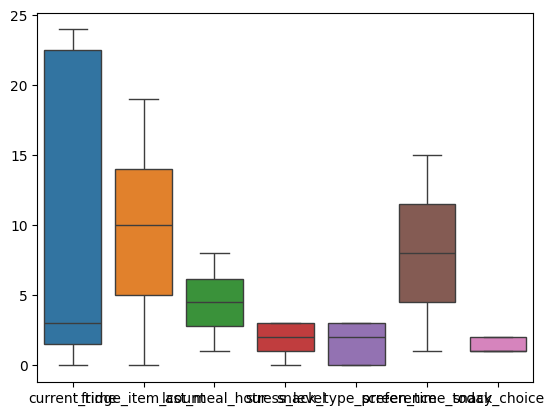

In [11]:
sns.boxplot(df)

In [14]:
x_train,x_test,y_train,y_test = train_test_split(x,y, test_size = 0.15, random_state = 42)

In [20]:
# scale these values
scaler = MinMaxScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [ ]:
# Data Drifting: 

# its good idea to split the data into training and testing before the scaling.
# otherwise the patterns of training data will pass to testing data.

In [19]:
x_train_scaled.shape

(51000, 6)

In [21]:
x_test_scaled.shape

(9000, 6)

In [22]:
# train the naive bayes: Goussian Naive bayes
from sklearn.naive_bayes import GaussianNB

In [26]:
model = GaussianNB()
model.fit(x_train_scaled,y_train)

,priors,None
,var_smoothing,1e-09


In [27]:
model.score(x_test_scaled, y_test)

0.6536666666666666

In [28]:
# Prediction
pawan = [[0,15,8,1,3,4]]
model.predict(pawan)

# GaussianNB: when we have normal distributed data.

array([1], dtype=int64)

In [29]:
# categorical Naive Bayes: when the data is categorical (even with multiple categories.)
from sklearn.naive_bayes import CategoricalNB
model_obj = CategoricalNB()
model_obj.fit(x_train_scaled,y_train)

,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None
,min_categories,None


In [30]:
model_obj.score(x_test_scaled, y_test)

0.6536666666666666

In [31]:
# Multinomial Naive Bayes: depends upon word frequencies.
from sklearn.naive_bayes import MultinomialNB
model_obj = MultinomialNB()
model_obj.fit(x_train_scaled,y_train)

,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None


In [32]:
model_obj.score(x_test_scaled,y_test)

0.6536666666666666

In [34]:
# Bernoulli Naive Bayes: Features are in binary (eg: happy and sad)
from sklearn.naive_bayes import BernoulliNB
model_obj = BernoulliNB()
model_obj.fit(x_train_scaled,y_train)
model_obj.score(x_test_scaled,y_test)

0.6536666666666666